# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Alexis Rivera Aguilera

* **Matrícula:** A01840517

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap

from pathlib import Path
import platform
import sklearn
import xgboost
import imblearn

from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, brier_score_loss, log_loss,
    confusion_matrix, PrecisionRecallDisplay
)


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [39]:
from sklearn.inspection import permutation_importance

print('Versiones de ejecución:')
print({'Python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
       'imbalanced-learn': imblearn.__version__, 'xgboost': xgboost.__version__,
       'shap': shap.__version__})

carpetas = [Path('.'), Path('upload'), Path('../upload'), Path('/content')]
nombres_csv = ['fintech_default_risk(1).csv', 'fintech_default_risk.csv']
candidatos = [carpeta / nombre for carpeta in carpetas for nombre in nombres_csv]
ruta_csv = next((ruta for ruta in candidatos if ruta.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError('Carga fintech_default_risk(1).csv junto al notebook.')
print('Archivo utilizado:', ruta_csv)

Versiones de ejecución:
{'Python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1', 'shap': '0.54.1'}
Archivo utilizado: fintech_default_risk.csv


In [40]:
# Cargamos los datos y obtenemos alguna información básica:

#df = pd.read_csv('fintech_default_risk.csv')
pd.read_csv(ruta_csv)

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [41]:
print('Valores faltantes:', int(df.isna().sum().sum()))
print('Filas duplicadas exactas:', int(df.duplicated().sum()))
print('Valores de la variable objetivo:', sorted(df['default_90d'].unique()))
assert set(df['default_90d'].unique()) == {0, 1}
assert not df.isna().any().any(), 'Revisar una imputación dentro de cada fold de entrenamiento.'
assert df.duplicated().sum() == 0, 'Revisar duplicados antes de dividir los datos.'

print('\nEvidencia descriptiva; esta variable NO entrará al modelo corregido:')
display(df.groupby('default_90d')['dias_max_atraso_30d_despues'].agg(['count', 'min', 'max', 'mean']))

print('\nSegmento premium: conteos descriptivos, no evidencia causal:')
display(pd.crosstab(df['cliente_premium'], df['default_90d']))
print('Diferencia máxima en la razón deuda / ingreso:',
      np.max(np.abs(df['relacion_deuda_ingreso'] - df['deuda_total'] / df['ingreso_mensual'])))

Valores faltantes: 0
Filas duplicadas exactas: 0
Valores de la variable objetivo: [np.int64(0), np.int64(1)]

Evidencia descriptiva; esta variable NO entrará al modelo corregido:


,count,min,max,mean
default_90d,,,,
0,4414,0,9,4.47440
1,586,15,89,52.46587



Segmento premium: conteos descriptivos, no evidencia causal:


default_90d,0,1
cliente_premium,,
0,3317,435
1,1097,151


Diferencia máxima en la razón deuda / ingreso: 0.0008203172384737556


In [42]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target, "dias_max_atraso_30d_despues"])
y = df[target]

In [43]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

# Primero se separan observaciones reales; no se aplica SMOTE a toda la base.
X_train, X_rest, y_train, y_rest = train_test_split(
    X,
    y,
    test_size=0.30,  # Conservamos el 70% para entrenar.
    random_state=RANDOM_STATE,  # semilla
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_rest,
    y_rest,
    test_size=0.50,  # La mitad del 30%: 15% validación y 15% prueba.
    random_state=RANDOM_STATE,  # semilla
    stratify=y_rest
)

for etiqueta, salida in [('Entrenamiento', y_train), ('Validación', y_val), ('Prueba', y_test)]:
    print(f'{etiqueta}: n={len(salida)}, positivos={int(salida.sum())}, tasa={salida.mean():.2%}')

assert not set(X_train.index) & set(X_val.index)
assert not set(X_train.index) & set(X_test.index)
assert not set(X_val.index) & set(X_test.index)
assert 'dias_max_atraso_30d_despues' not in X_train.columns

Entrenamiento: n=3500, positivos=410, tasa=11.71%
Validación: n=750, positivos=88, tasa=11.73%
Prueba: n=750, positivos=88, tasa=11.73%


El primer train_test_split reserva 30%. El segundo divide esa reserva a la mitad. stratify mantiene aproximadamente la proporción de incumplimientos. Los assert comprueban que las filas no se comparten. No se dispone de fecha ni ID de cliente: esta separación aleatoria es una evaluación académica provisional, no sustituye una validación temporal ni por cliente.

Nº	Error o limitación detectada	| Consecuencia	| Corrección o recomendación

1.	Se incluye dias_max_atraso_30d_despues.	Se predice usando el futuro; el desempeño puede parecer perfecto.	Excluirla y verificar disponibilidad temporal de cada atributo.

2.	SMOTE.fit_resample(X, y) ocurre antes de dividir.	Observaciones relacionadas por interpolación pueden quedar en ambos conjuntos.	Dividir primero; aquí se prescinde del remuestreo. Si se ensaya después, usar Pipeline dentro de cada fold de entrenamiento.

3.	La prueba contiene datos sintéticos y una proporción balanceada.	Accuracy, probabilidades y utilidad por 10,000 no representan la población real.	Validación y prueba conservan observaciones y prevalencia reales.

4.	Se optimiza el umbral con y_test.	Se adapta una decisión a la prueba, sesgando la estimación final.	Elegir el umbral solamente con validación.

5.	Solo se reporta accuracy.	Predecir siempre 0 ya logra 88.28% en la base completa y no detecta ningún incumplimiento.	Complementar con AP, ROC-AUC, recall, precisión, F1, balanced accuracy, calibración y utilidad.

6.	Se asigna y_probs[2] como mejor modelo.	Se favorece XGBoost sin una comparación económica justificable.	Comparar los tres modelos y sus umbrales en validación.

7.	Se usan hiperparámetros por defecto sin validación cruzada.	No se controla explícitamente la complejidad ni se mide estabilidad.	Ajustar una malla acotada con CV estratificada y regularización.

8.	Se interpreta Train/Test alto como ausencia de sobreajuste aun con fuga.	Una partición contaminada no demuestra generalización.	Examinar brechas train/CV/validación luego de excluir la fuga.

9.	Se usan probabilidades sin evaluar calibración y tras alterar la prevalencia.	Un valor 0.2 puede no equivaler a un riesgo real de 20%.	Calibración sigmoide mediante predicciones fuera de fold y evaluación Brier/log loss.

10.	La matriz utiliza las variables residuales modelo y nombre del último ciclo.	Puede mostrar el último modelo y umbral 0.5 aunque se haya elegido otro.	Usar explícitamente el modelo seleccionado y su umbral fijado.

11.	Se fija una interpretación SHAP con f(x)=8.174 sin recalcularla.	La explicación deja de corresponder a datos, modelo o cliente actuales.	Generar la explicación del modelo elegido y distinguir salida base de probabilidad calibrada.

12.	Se omite estratificación y no hay validación temporal/por cliente.	Puede variar la prevalencia; no se demuestra generalización a meses o clientes nuevos.	Estratificar ahora; solicitar fechas e identificadores para una validación de producción.

13.	La malla original no contempla políticas extremas y el incremento divide por una utilidad que podría ser cero.	Puede omitirse rechazar/aprobar todo y fallar la comparación porcentual.	Incluir extremos y proteger la división por cero.

14.	No se contrasta la utilidad con aprobar todo ni se cuantifica incertidumbre.	Un modelo positivo puede ser peor que una política simple.	Comparar ambas políticas e incluir intervalos bootstrap pareados.


# **Configuración y Entrenamiento de los Modelos**

In [44]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

especificaciones = {
    'Árbol de Decisión': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'max_depth': [3, 5, 7], 'min_samples_leaf': [20, 50], 'ccp_alpha': [0.0, 0.001]}
    ),
    'Random Forest': (
        RandomForestClassifier(n_estimators=250, n_jobs=1, random_state=RANDOM_STATE),
        {'max_depth': [5, 8, None], 'min_samples_leaf': [10, 30], 'max_features': ['sqrt', 1.0]}
    ),
    'XGBoost': (
        XGBClassifier(eval_metric='logloss', tree_method='hist', n_jobs=1,
                      subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE),
        {'max_depth': [2, 3], 'n_estimators': [150, 300],
         'learning_rate': [0.03, 0.07], 'reg_lambda': [1.0, 10.0]}
    )
}

busquedas = {}
mejores_parametros = {}
filas_cv = []

for nombre, (estimador, malla) in especificaciones.items():
    busqueda = GridSearchCV(
        estimador, malla, scoring={'logloss': 'neg_log_loss', 'ap': 'average_precision'},
        refit='logloss', cv=cv, return_train_score=True, n_jobs=1, error_score='raise'
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    mejores_parametros[nombre] = busqueda.best_params_
    i = busqueda.best_index_
    filas_cv.append({
        'Modelo': nombre,
        'Logloss_train_CV': -busqueda.cv_results_['mean_train_logloss'][i],
        'Logloss_validacion_CV': -busqueda.cv_results_['mean_test_logloss'][i],
        'SD_logloss_CV': busqueda.cv_results_['std_test_logloss'][i],
        'AP_train_CV': busqueda.cv_results_['mean_train_ap'][i],
        'AP_validacion_CV': busqueda.cv_results_['mean_test_ap'][i],
        'SD_AP_CV': busqueda.cv_results_['std_test_ap'][i]
    })
    print(nombre, 'mejores parámetros:', busqueda.best_params_)

tabla_cv = pd.DataFrame(filas_cv).set_index('Modelo')
display(tabla_cv.round(4))

Árbol de Decisión mejores parámetros: {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 50}
Random Forest mejores parámetros: {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 30}
XGBoost mejores parámetros: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'reg_lambda': 10.0}


,Logloss_train_CV,Logloss_validacion_CV,SD_logloss_CV,AP_train_CV,AP_validacion_CV,SD_AP_CV
Modelo,,,,,,
Árbol de Decisión,0.2913,0.3009,0.0129,0.3730,0.3582,0.0361
Random Forest,0.2620,0.2943,0.0162,0.5176,0.4235,0.0556
XGBoost,0.2605,0.2881,0.0130,0.5355,0.4284,0.0495


In [45]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE,  # semilla
                            **mejores_parametros['Árbol de Decisión'])
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE,  # semilla
                            n_estimators=250, n_jobs=1,
                            **mejores_parametros['Random Forest'])
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE,  # semilla
                    tree_method='hist', n_jobs=1, subsample=0.8, colsample_bytree=0.8,
                    **mejores_parametros['XGBoost'])
xgb.fit(X_train, y_train)

modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}
modelos_base = modelos.copy()

# La calibración recibe solo entrenamiento. ensemble=False conserva un estimador base final.
modelos = {
    nombre: CalibratedClassifierCV(
        estimator=clone(modelo), method='sigmoid', cv=cv, ensemble=False, n_jobs=1
    ).fit(X_train, y_train)
    for nombre, modelo in modelos_base.items()
}

y_probs = []   # Probabilidades de VALIDACIÓN: 0:DT, 1:RF, 2:XGBoost.
filas_metricas = []
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():
    y_pred_train = modelo.predict(X_train)
    y_pred_val = modelo.predict(X_val)
    y_probs.append(modelo.predict_proba(X_val)[:,1])

    acc_train = accuracy_score(y_train, y_pred_train)
    acc_val = accuracy_score(y_val, y_pred_val)
    print(f"{nombre}:")
    print(f"Train: {acc_train:.4f}")
    print(f"Validación: {acc_val:.4f}")
    print("+"*20)

    for conjunto, entradas, reales in [('Train', X_train, y_train), ('Validación', X_val, y_val)]:
        prob = modelo.predict_proba(entradas)[:, 1]
        pred = (prob >= 0.5).astype(int)
        filas_metricas.append({
            'Modelo': nombre, 'Conjunto': conjunto,
            'Accuracy': accuracy_score(reales, pred),
            'Balanced_accuracy': balanced_accuracy_score(reales, pred),
            'AP': average_precision_score(reales, prob),
            'ROC_AUC': roc_auc_score(reales, prob),
            'Recall_0.5': recall_score(reales, pred, zero_division=0),
            'Precision_0.5': precision_score(reales, pred, zero_division=0),
            'F1_0.5': f1_score(reales, pred, zero_division=0),
            'Brier': brier_score_loss(reales, prob), 'Logloss': log_loss(reales, prob)
        })

tabla_metricas = pd.DataFrame(filas_metricas)
display(tabla_metricas.round(4))

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 0.8923
Validación: 0.8880
++++++++++++++++++++
Random Forest:
Train: 0.8997
Validación: 0.8880
++++++++++++++++++++
XGBoost:
Train: 0.8994
Validación: 0.8947
++++++++++++++++++++


,Modelo,Conjunto,Accuracy,Balanced_accuracy,AP,ROC_AUC,Recall_0.5,Precision_0.5,F1_0.5,Brier,Logloss
0,Árbol de Decisión,Train,0.8923,0.5572,0.3836,0.7818,0.1195,0.7538,0.2063,0.0847,0.2963
1,Árbol de Decisión,Validación,0.8880,0.5326,0.3426,0.7544,0.0682,0.7500,0.1250,0.0873,0.3051
2,Random Forest,Train,0.8997,0.6153,0.5115,0.8558,0.2439,0.7092,0.3630,0.0787,0.2736
3,Random Forest,Validación,0.8880,0.5769,0.4164,0.7998,0.1705,0.5769,0.2632,0.0855,0.2966
4,XGBoost,Train,0.8994,0.6194,0.5231,0.8526,0.2537,0.6933,0.3714,0.0775,0.2706
5,XGBoost,Validación,0.8947,0.6004,0.4482,0.8091,0.2159,0.6552,0.3248,0.0839,0.2911


In [46]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500

In [47]:
umbral_teorico = GANANCIA_BUENO / (GANANCIA_BUENO - PERDIDA_DEFAULT)
thresholds = np.unique(np.r_[np.arange(0.0, 1.001, 0.01),
                             umbral_teorico, np.nextafter(1.0, np.inf)])

def ganancias_individuales(y_true, y_prob, threshold):
    reales = np.asarray(y_true)
    aprobar = np.asarray(y_prob) < threshold
    return np.where(aprobar, np.where(reales == 0, GANANCIA_BUENO, PERDIDA_DEFAULT), 0)

filas_seleccion = []
umbrales_por_modelo = {}
for (nombre, modelo), prob in zip(modelos.items(), y_probs):
    beneficios = np.array([ganancias_individuales(y_val, prob, th).sum() for th in thresholds])
    posicion = int(np.argmax(beneficios))
    th = float(thresholds[posicion])
    umbrales_por_modelo[nombre] = th
    filas_seleccion.append({
        'Modelo': nombre, 'Umbral_validacion': th,
        'Utilidad_val_USD': int(beneficios[posicion]),
        'Utilidad_val_10000': beneficios[posicion] * 10000 / len(y_val),
        'Utilidad_val_0.5': int(ganancias_individuales(y_val, prob, 0.5).sum()),
        'AP': average_precision_score(y_val, prob),
        'Brier': brier_score_loss(y_val, prob)
    })

tabla_seleccion = pd.DataFrame(filas_seleccion).sort_values(
    ['Utilidad_val_USD', 'Brier'], ascending=[False, True], kind='stable'
).reset_index(drop=True)
nombre_mejor_modelo = tabla_seleccion.loc[0, 'Modelo']
mejor_modelo = modelos[nombre_mejor_modelo]
umbral_fijado = float(tabla_seleccion.loc[0, 'Umbral_validacion'])
y_probs_mejor_modelo_val = mejor_modelo.predict_proba(X_val)[:, 1]
modelo_base_mejor = mejor_modelo.calibrated_classifiers_[0].estimator

display(tabla_seleccion.round(4))
print('Decisión fijada antes de evaluar prueba:', nombre_mejor_modelo, 'umbral =', umbral_fijado)
print('Aprobar todo en validación (USD):', int(np.where(y_val == 0, 100, -500).sum()))
print('Rechazar todo en validación (USD): 0')

,Modelo,Umbral_validacion,Utilidad_val_USD,Utilidad_val_10000,Utilidad_val_0.5,AP,Brier
0,XGBoost,0.1400,39400,525333.3333,30700,0.4482,0.0839
1,Random Forest,0.1667,38900,518666.6667,28600,0.4164,0.0855
2,Árbol de Decisión,0.1100,35700,476000.0000,25000,0.3426,0.0873


Decisión fijada antes de evaluar prueba: XGBoost umbral = 0.14
Aprobar todo en validación (USD): 22200
Rechazar todo en validación (USD): 0


,Modelo,Probabilidad,Brier_val,Logloss_val
0,Árbol de Decisión,Base,0.0873,0.3044
1,Árbol de Decisión,Calibrado,0.0873,0.3051
2,Random Forest,Base,0.0853,0.2929
3,Random Forest,Calibrado,0.0855,0.2966
4,XGBoost,Base,0.0837,0.2871
5,XGBoost,Calibrado,0.0839,0.2911


Referencia constante de entrenamiento; Brier en validación: 0.1036


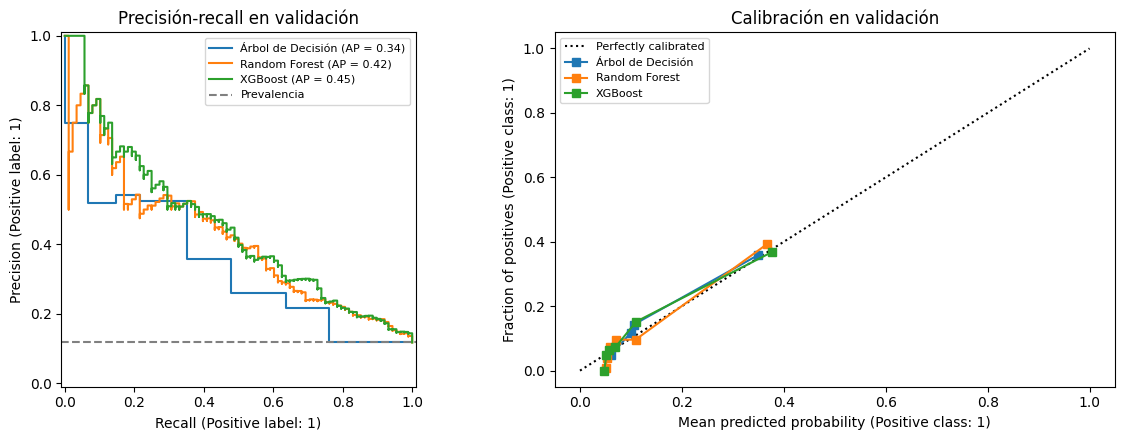

Árbol de Decisión: brecha AP train-CV = 0.0148; brecha log loss CV-train = 0.0096.
Random Forest: brecha AP train-CV = 0.0941; brecha log loss CV-train = 0.0323.
XGBoost: brecha AP train-CV = 0.1071; brecha log loss CV-train = 0.0276.


In [48]:
filas_calibracion = []
for nombre in modelos:
    for tipo, modelo in [('Base', modelos_base[nombre]), ('Calibrado', modelos[nombre])]:
        prob = modelo.predict_proba(X_val)[:, 1]
        filas_calibracion.append({'Modelo': nombre, 'Probabilidad': tipo,
            'Brier_val': brier_score_loss(y_val, prob), 'Logloss_val': log_loss(y_val, prob)})
display(pd.DataFrame(filas_calibracion).round(4))

p_constante_val = np.repeat(y_train.mean(), len(y_val))
print('Referencia constante de entrenamiento; Brier en validación:',
      round(brier_score_loss(y_val, p_constante_val), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_val)[:, 1]
    PrecisionRecallDisplay.from_predictions(y_val, prob, name=nombre, ax=axes[0])
    CalibrationDisplay.from_predictions(y_val, prob, n_bins=6, strategy='quantile',
                                        name=nombre, ax=axes[1])
axes[0].axhline(y_val.mean(), color='gray', linestyle='--', label='Prevalencia')
axes[0].set_title('Precisión-recall en validación')
axes[0].legend(fontsize=8)
axes[1].set_title('Calibración en validación')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for nombre, fila in tabla_cv.iterrows():
    print(f"{nombre}: brecha AP train-CV = {fila['AP_train_CV'] - fila['AP_validacion_CV']:.4f}; "
          f"brecha log loss CV-train = {fila['Logloss_validacion_CV'] - fila['Logloss_train_CV']:.4f}.")

diagnostico_ajuste = '**Diagnóstico de esta ejecución:**\n\n'
for nombre, fila in tabla_cv.iterrows():
    diagnostico_ajuste += (
        f"- **{nombre}**: AP train/CV = {fila['AP_train_CV']:.4f}/{fila['AP_validacion_CV']:.4f}; "
        f"log loss train/CV = {fila['Logloss_train_CV']:.4f}/{fila['Logloss_validacion_CV']:.4f}.\n"
    )

En esta ejecución las brechas son mayores en Random Forest y XGBoost que en el árbol simple: hay sobreajuste residual, aunque se regularizaron los modelos. Las diferencias de accuracy son pequeñas y ocultarían parte de esta evidencia. El árbol muestra una brecha menor y menor AP fuera de entrenamiento: es compatible con una restricción mayor de capacidad, pero no demuestra por sí sola subajuste. Los tres superan claramente la referencia de AP cercana a 0.117, por lo que no hay evidencia de ausencia total de aprendizaje. Las desviaciones entre folds muestran variabilidad; no constituyen intervalos de confianza ni una prueba de superioridad entre modelos.

Una AP mucho mayor en entrenamiento que en CV, o un log loss mucho menor en entrenamiento, evidencia sobreajuste dentro de la búsqueda. Las tablas y curvas externas permiten valorar si la regularización fue suficiente. Un rendimiento bajo tanto en entrenamiento como fuera de él podría sugerir subajuste, pero también poca señal o ruido; no basta una accuracy alta para distinguirlos.

# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [49]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                    Variable  Importancia
4        utilizacion_credito     0.450832
6          consultas_buro_6m     0.203585
3           score_crediticio     0.164849
10    relacion_deuda_ingreso     0.069836
1            ingreso_mensual     0.025370
9                deuda_total     0.023278
2   antiguedad_laboral_meses     0.016424
8             limite_credito     0.015993
0                       edad     0.015563
5                atrasos_12m     0.009161


,Variable,Aumento_logloss,SD_permutacion
0,utilizacion_credito,0.04426,0.00962
1,consultas_buro_6m,0.04234,0.00798
2,score_crediticio,0.02556,0.00521
3,relacion_deuda_ingreso,0.01128,0.00313
4,atrasos_12m,0.00293,0.00215
5,deuda_total,0.00048,0.00065
6,num_productos,0.00034,0.00058
7,limite_credito,0.00033,0.00051
8,cliente_premium,0.00000,0.00000
9,edad,-0.00028,0.00034


,Variable,Aumento_logloss,SD_permutacion,Significado de negocio
0,utilizacion_credito,0.044258,0.009619,Fracción de la línea de crédito utilizada. Un ...
1,consultas_buro_6m,0.042339,0.007977,Consultas al buró en seis meses; puede refleja...
2,score_crediticio,0.025563,0.005209,Puntaje interno de historial crediticio (300-8...
3,relacion_deuda_ingreso,0.011284,0.003132,Deuda total dividida entre ingreso mensual; in...


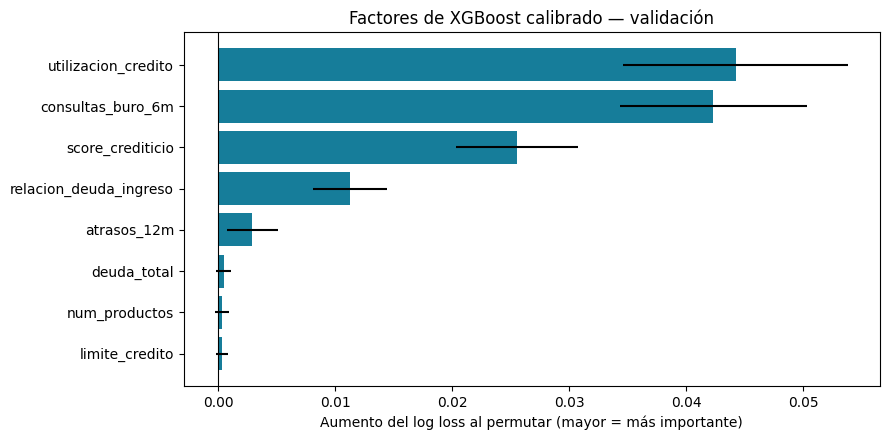

In [50]:
permutacion = permutation_importance(
    mejor_modelo, X_val, y_val, scoring='neg_log_loss',
    n_repeats=15, random_state=RANDOM_STATE, n_jobs=1
)
tabla_factores = pd.DataFrame({
    'Variable': X_val.columns,
    'Aumento_logloss': permutacion.importances_mean,
    'SD_permutacion': permutacion.importances_std
}).sort_values('Aumento_logloss', ascending=False).reset_index(drop=True)
display(tabla_factores.round(5))

significados = {
    'edad': 'Edad del solicitante. Puede capturar diferencias entre perfiles; no demuestra que la edad cause incumplimiento.',
    'ingreso_mensual': 'Ingreso mensual declarado en USD; representa capacidad de pago. Deben verificarse unidades y fecha de medición.',
    'antiguedad_laboral_meses': 'Meses en el empleo actual; aproxima estabilidad laboral y de ingresos.',
    'score_crediticio': 'Puntaje interno de historial crediticio (300-850). El diccionario asocia valores mayores con menor riesgo histórico.',
    'utilizacion_credito': 'Fracción de la línea de crédito utilizada. Un uso elevado puede indicar menor holgura financiera.',
    'atrasos_12m': 'Pagos tardíos durante los doce meses anteriores; resume comportamiento previo de pago.',
    'consultas_buro_6m': 'Consultas al buró en seis meses; puede reflejar búsqueda reciente de financiamiento.',
    'num_productos': 'Número de productos financieros activos; describe amplitud de la relación con la institución.',
    'limite_credito': 'Crédito autorizado; debe corresponder al límite conocido antes de esta decisión.',
    'deuda_total': 'Saldo de deuda vigente al evaluar; refleja compromisos financieros existentes.',
    'relacion_deuda_ingreso': 'Deuda total dividida entre ingreso mensual; indica apalancamiento, no porcentaje de cuota mensual.',
    'cliente_premium': 'Segmento comercial binario. Debe estar definido antes de evaluar; no se interpreta como causa de menor riesgo.'
}
top4 = tabla_factores.head(4).copy()
top4['Significado de negocio'] = top4['Variable'].map(significados)
display(top4)

fig, ax = plt.subplots(figsize=(9, 4.5))
grafica = tabla_factores.head(8).iloc[::-1]
ax.barh(grafica['Variable'], grafica['Aumento_logloss'], xerr=grafica['SD_permutacion'], color='#167d9a')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Aumento del log loss al permutar (mayor = más importante)')
ax.set_title(f'Factores de {nombre_mejor_modelo} calibrado — validación')
plt.tight_layout()
plt.show()

permutation_importance mezcla una columna de validación y mide cuánto empeora el log loss del predictor calibrado. Repite 15 veces con semilla 11; la desviación estándar mide variación entre permutaciones, no un intervalo de confianza poblacional. Un aumento cercano a cero o negativo señala una contribución débil/inestable. La importancia no indica por sí sola si aumentar el factor sube o baja el riesgo. Las variables correlacionadas —deuda, límite, utilización y razón deuda/ingreso— pueden sustituirse y repartir importancia; la lectura es asociativa.

Modelo: XGBoost | Escala SHAP: log-odds


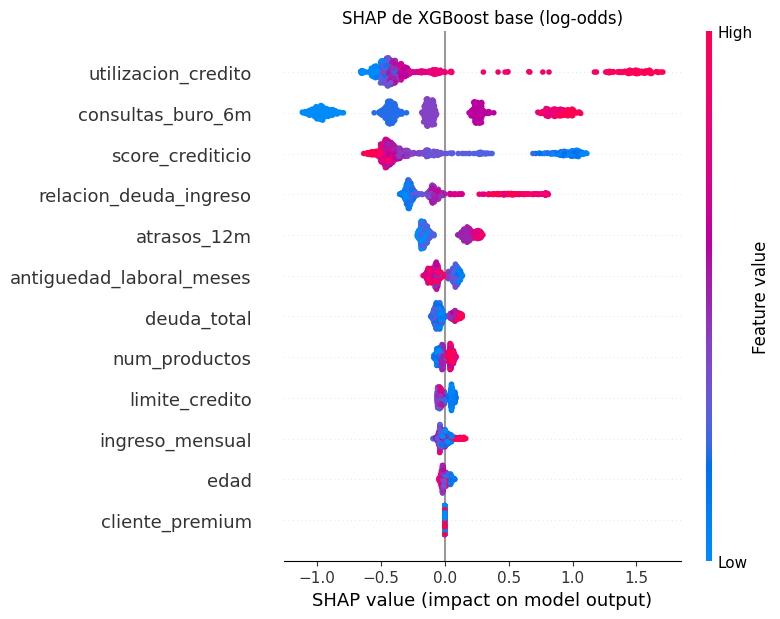

In [51]:
# SHAP del estimador base del modelo seleccionado en validación.
# La explicación es de la salida BASE; la probabilidad final usa además calibración.
explainer = shap.TreeExplainer(modelo_base_mejor)

shap_values = explainer.shap_values(X_val)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif np.asarray(shap_values).ndim == 3:
    shap_values = shap_values[:, :, 1]

base_shap = float(np.asarray(explainer.expected_value).ravel()[-1])
escala_shap = 'log-odds' if nombre_mejor_modelo == 'XGBoost' else 'probabilidad base'
print('Modelo:', nombre_mejor_modelo, '| Escala SHAP:', escala_shap)

shap.summary_plot(
    shap_values,
    X_val,
    show=False
)
plt.title(f'SHAP de {nombre_mejor_modelo} base ({escala_shap})')
plt.tight_layout()
plt.show()

SHAP debe corresponder al modelo elegido, no necesariamente a XGBoost. Se usa validación para explicar antes de abrir prueba y se extrae la clase 1 cuando el explicador devuelve ambas clases. Se explicita que la suma SHAP explica el estimador base, no la transformación sigmoide posterior.

TreeExplainer calcula contribuciones por variable. SHAP positivo aumenta la salida base y negativo la reduce. Para XGBoost la salida base es log-odds; para los árboles de scikit-learn es probabilidad. La importancia por permutación anterior sí evalúa el predictor calibrado completo.

## **Seleccionemos y analicemos un cliente en Particular:**

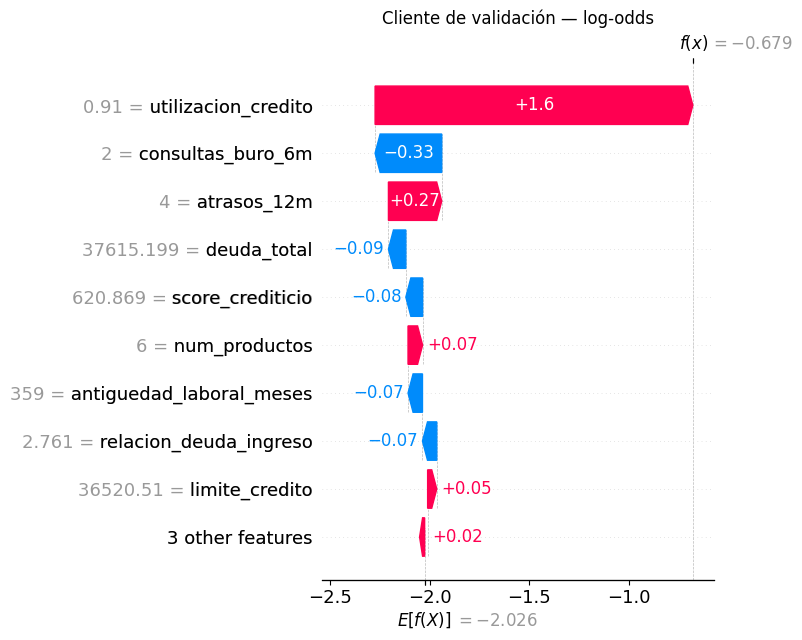

Índice de fila del cliente en CSV (base 0): 4189
Mayor contribución absoluta: utilizacion_credito
Base SHAP: -2.02585 | Salida reconstruida: -0.67906
Probabilidad base: 0.33647
Probabilidad calibrada: 0.2969
Decisión con 0.5: Aprobar
Decisión con umbral validado: Rechazar


In [52]:
# Analicemos un cliente de validación con el modelo seleccionado.
cliente = X_val.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)
if isinstance(shap_values_cliente, list):
    shap_values_cliente = shap_values_cliente[1]
elif np.asarray(shap_values_cliente).ndim == 3:
    shap_values_cliente = shap_values_cliente[:, :, 1]

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=base_shap,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    ),
    show=False
)
plt.title(f'Cliente de validación — {escala_shap}')
plt.tight_layout()
plt.show()

prob_cliente_base = float(modelo_base_mejor.predict_proba(cliente)[0, 1])
prob_cliente_final = float(mejor_modelo.predict_proba(cliente)[0, 1])
salida_shap_cliente = float(base_shap + shap_values_cliente[0].sum())
indice_factor = int(np.argmax(np.abs(shap_values_cliente[0])))
print('Índice de fila del cliente en CSV (base 0):', int(cliente.index[0]))
print('Mayor contribución absoluta:', cliente.columns[indice_factor])
print('Base SHAP:', round(base_shap, 5), '| Salida reconstruida:', round(salida_shap_cliente, 5))
print('Probabilidad base:', round(prob_cliente_base, 5))
print('Probabilidad calibrada:', round(prob_cliente_final, 5))
print('Decisión con 0.5:', 'Aprobar' if prob_cliente_final < 0.5 else 'Rechazar')
print('Decisión con umbral validado:', 'Aprobar' if prob_cliente_final < umbral_fijado else 'Rechazar')

iloc[[11]] selecciona la duodécima fila manteniendo una tabla de una fila. El waterfall parte de base_shap y suma contribuciones. La decisión final compara la probabilidad calibrada con el umbral económico; esa probabilidad no es necesariamente la suma SHAP del modelo base.

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

# **Análisis desde la perspectiva del negocio:**

In [53]:
#GANANCIA_BUENO = 100
#PERDIDA_DEFAULT = -500


La clase positiva 1 significa incumplimiento y conduce a rechazo cuando p >= threshold. La clase negativa 0 conduce a aprobación. Por tanto, TN es un buen pagador aprobado (+100 USD); FN es un incumplidor aprobado (-500 USD); FP es un buen pagador rechazado (0 de utilidad directa y una oportunidad perdida); TP es un incumplidor rechazado (0 de utilidad directa).

La utilidad observada es 100 × TN − 500 × FN. Se usa como estimador empírico de utilidad esperada. Los importes son los del enunciado: no se agregan intereses, costos de revisión ni recuperaciones no proporcionados.

In [54]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += GANANCIA_BUENO

            else:
                utilidad_total += PERDIDA_DEFAULT

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = mejor_modelo.predict_proba(X_test)[:, 1]  # Modelo elegido en validación

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Utilidad de prueba (USD) con umbral 0.5:")
print(utilidad_05)

Utilidad de prueba (USD) con umbral 0.5:
30300


aprobar es un vector booleano. zip recorre cada resultado real y su decisión. Un aprobado que paga suma 100; un aprobado que incumple resta 500; un rechazado aporta cero. La regla conserva el comparador <; en igualdad se rechaza.

Mejor umbral de la malla en validación: 0.14
Mayor utilidad de validación (USD): 39400


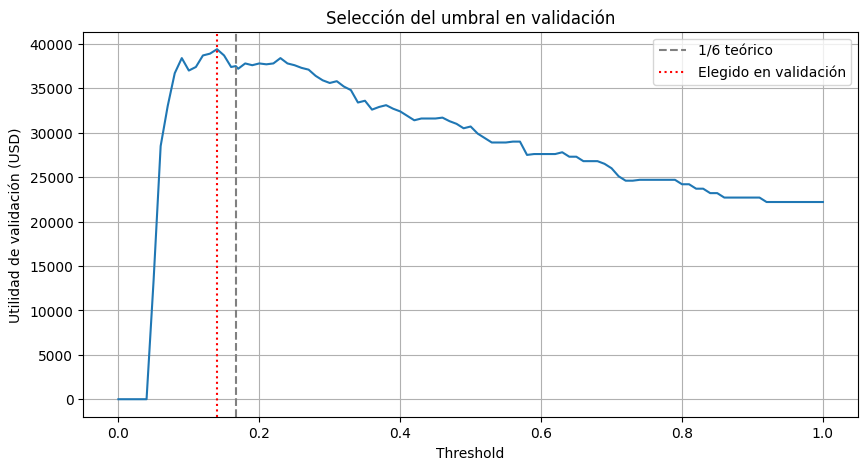

In [55]:
# Reproducimos la búsqueda del umbral SOLO en validación (modelo ya elegido):

thresholds = np.unique(np.r_[np.arange(0.0, 1.001, 0.01),
                             umbral_teorico, np.nextafter(1.0, np.inf)])

utilidades = []

for th in thresholds:

    u = ganancias_individuales(
        y_val,
        y_probs_mejor_modelo_val,
        threshold=th
    ).sum()

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

assert best_threshold == umbral_fijado
print('Mejor umbral de la malla en validación:', best_threshold)
print('Mayor utilidad de validación (USD):', best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad de validación (USD)")
plt.title("Selección del umbral en validación")
plt.axvline(umbral_teorico, color="gray", linestyle="--", label="1/6 teórico")
plt.axvline(best_threshold, color="red", linestyle=":", label="Elegido en validación")
plt.legend()
plt.grid()

plt.show()

np.arange genera la malla; ganancias_individuales(...).sum() calcula el beneficio de cada política. np.argmax obtiene el primer máximo. El gráfico muestra únicamente validación. Un umbral más bajo rechaza más solicitudes: puede disminuir pérdidas, pero también elimina utilidad de buenos pagadores.

In [56]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



Se conserva completa la función original. Primero suma el beneficio de las aprobaciones y después multiplica por 10_000 / len(y_true). El denominador es el total de solicitudes evaluadas, no el número aprobado. total_aprobados se conserva aunque la función original no lo devuelve.

In [57]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100 if profit_default != 0 else np.nan

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Umbral elegido en validación : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $404,000
Umbral elegido en validación : $558,667
Diferencia : $154,667
Incremento : 38.3%


delta es la diferencia en USD por 10,000. incremento_pct divide esa diferencia por la magnitud de la utilidad inicial; si la base fuera cero se muestra NaN porque el porcentaje no está definido.

In [58]:
def resumen_politica(etiqueta, y_real, prob, umbral):
    pred = (np.asarray(prob) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    ganancias = ganancias_individuales(y_real, prob, umbral)
    assert ganancias.sum() == GANANCIA_BUENO * tn + PERDIDA_DEFAULT * fn
    return {
        'Política': etiqueta, 'Umbral': umbral, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Aprobados': tn + fn, 'Tasa_aprobacion': (tn + fn) / len(y_real),
        'Default_entre_aprobados': fn / (tn + fn) if tn + fn else np.nan,
        'Accuracy': accuracy_score(y_real, pred),
        'Balanced_accuracy': balanced_accuracy_score(y_real, pred),
        'Recall': recall_score(y_real, pred, zero_division=0),
        'Precision': precision_score(y_real, pred, zero_division=0),
        'F1': f1_score(y_real, pred, zero_division=0),
        'Utilidad_USD': ganancias.sum(), 'Utilidad_10000': ganancias.mean() * 10000
    }

tabla_politicas = pd.DataFrame([
    resumen_politica('Umbral 0.50', y_test, y_probs_mejor_modelo, 0.5),
    resumen_politica('Umbral teórico 1/6', y_test, y_probs_mejor_modelo, umbral_teorico),
    resumen_politica('Umbral validado', y_test, y_probs_mejor_modelo, best_threshold),
    resumen_politica('Aprobar todo', y_test, y_probs_mejor_modelo, np.nextafter(1.0, np.inf)),
    resumen_politica('Rechazar todo', y_test, y_probs_mejor_modelo, 0.0)
])
display(tabla_politicas[['Política', 'Umbral', 'TN', 'FP', 'FN', 'TP',
                        'Aprobados', 'Tasa_aprobacion', 'Default_entre_aprobados']].round(4))
display(tabla_politicas[['Política', 'Accuracy', 'Balanced_accuracy', 'Recall',
                        'Precision', 'F1', 'Utilidad_USD', 'Utilidad_10000']].round(4))

# Comparación diagnóstica de los tres candidatos con sus umbrales ya congelados.
# No se cambia el ganador después de observar estos resultados.
filas_prueba = []
for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_test)[:, 1]
    resumen = resumen_politica(nombre, y_test, prob, umbrales_por_modelo[nombre])
    resumen.update({'AP': average_precision_score(y_test, prob),
                    'ROC_AUC': roc_auc_score(y_test, prob),
                    'Brier': brier_score_loss(y_test, prob),
                    'Logloss': log_loss(y_test, prob)})
    filas_prueba.append(resumen)
tabla_prueba = pd.DataFrame(filas_prueba).rename(columns={'Política': 'Modelo'})
display(tabla_prueba[['Modelo', 'AP', 'ROC_AUC', 'Brier', 'Logloss', 'Recall', 'Precision', 'F1']].round(4))
display(tabla_prueba[['Modelo', 'Umbral', 'TN', 'FP', 'FN', 'TP', 'Utilidad_USD', 'Utilidad_10000']].round(4))
print('Se mantiene el modelo elegido antes de prueba:', nombre_mejor_modelo)

g_05 = ganancias_individuales(y_test, y_probs_mejor_modelo, 0.5)
g_opt = ganancias_individuales(y_test, y_probs_mejor_modelo, best_threshold)
g_todos = np.where(np.asarray(y_test) == 0, GANANCIA_BUENO, PERDIDA_DEFAULT)
rng = np.random.default_rng(RANDOM_STATE)
indices_bootstrap = rng.integers(0, len(y_test), size=(2000, len(y_test)))

def intervalo_bootstrap(valores):
    medias = np.asarray(valores)[indices_bootstrap].mean(axis=1) * 10000
    return np.quantile(medias, [0.025, 0.975])

ci_utilidad = intervalo_bootstrap(g_opt)
ci_mejora_05 = intervalo_bootstrap(g_opt - g_05)
ci_mejora_todos = intervalo_bootstrap(g_opt - g_todos)
tabla_incertidumbre = pd.DataFrame([
    ['Utilidad umbral validado', g_opt.mean() * 10000, *ci_utilidad],
    ['Mejora frente a 0.5', (g_opt - g_05).mean() * 10000, *ci_mejora_05],
    ['Mejora frente a aprobar todo', (g_opt - g_todos).mean() * 10000, *ci_mejora_todos]
], columns=['Estimación por 10,000 (USD)', 'Punto', 'IC95_inferior', 'IC95_superior'])
display(tabla_incertidumbre.round(2))
assert utilidad(y_test, y_probs_mejor_modelo, best_threshold) == g_opt.sum()
assert np.isclose(utilidad_por_10000(y_test, y_probs_mejor_modelo, best_threshold), g_opt.mean() * 10000)

,Política,Umbral,TN,FP,FN,TP,Aprobados,Tasa_aprobacion,Default_entre_aprobados
0,Umbral 0.50,0.5000,648,14,69,19,717,0.9560,0.0962
1,Umbral teórico 1/6,0.1667,595,67,40,48,635,0.8467,0.0630
2,Umbral validado,0.1400,579,83,32,56,611,0.8147,0.0524
3,Aprobar todo,1.0000,662,0,88,0,750,1.0000,0.1173
4,Rechazar todo,0.0000,0,662,0,88,0,0.0000,NaN


,Política,Accuracy,Balanced_accuracy,Recall,Precision,F1,Utilidad_USD,Utilidad_10000
0,Umbral 0.50,0.8893,0.5974,0.2159,0.5758,0.3140,30300,404000.0000
1,Umbral teórico 1/6,0.8573,0.7221,0.5455,0.4174,0.4729,39500,526666.6667
2,Umbral validado,0.8467,0.7555,0.6364,0.4029,0.4934,41900,558666.6667
3,Aprobar todo,0.8827,0.5000,0.0000,0.0000,0.0000,22200,296000.0000
4,Rechazar todo,0.1173,0.5000,1.0000,0.1173,0.2100,0,0.0000


,Modelo,AP,ROC_AUC,Brier,Logloss,Recall,Precision,F1
0,Árbol de Decisión,0.3050,0.7541,0.0936,0.3197,0.4773,0.3925,0.4308
1,Random Forest,0.3718,0.8066,0.0891,0.3023,0.5341,0.3917,0.4519
2,XGBoost,0.4036,0.8258,0.0859,0.2925,0.6364,0.4029,0.4934


,Modelo,Umbral,TN,FP,FN,TP,Utilidad_USD,Utilidad_10000
0,Árbol de Decisión,0.1100,597,65,46,42,36700,489333.3333
1,Random Forest,0.1667,589,73,41,47,38400,512000.0000
2,XGBoost,0.1400,579,83,32,56,41900,558666.6667


Se mantiene el modelo elegido antes de prueba: XGBoost


,"Estimación por 10,000 (USD)",Punto,IC95_inferior,IC95_superior
0,Utilidad umbral validado,558666.67,465333.33,642666.67
1,Mejora frente a 0.5,154666.67,78666.67,241333.33
2,Mejora frente a aprobar todo,262666.67,169333.33,365333.33


La tabla de políticas muestra el costo del umbral: al rechazar más pueden evitarse incumplimientos, pero también aumenta el número de buenos pagadores rechazados. El comportamiento se compara con aprobar todo y rechazar todo, no solo con accuracy.

Los intervalos usan 2,000 remuestras pareadas de las mismas filas de prueba. Estiman incertidumbre muestral suponiendo observaciones independientes y un modelo y umbral fijos; no incluyen variación por reentrenamiento, selección ni cambios económicos. Si un intervalo de mejora incluye cero, no hay evidencia concluyente de una mejora positiva bajo este cálculo. Escalar a 10,000 es una proyección lineal, no una evaluación real de 10,000 clientes ni una utilidad garantizada.

Las etiquetas observadas corresponden a los clientes de la base. No se conoce cómo se seleccionaron ni qué habría ocurrido con clientes históricamente rechazados; por ello, la proyección no elimina el posible sesgo de selección y requiere validación prospectiva.

## **Matriz de Confusión**



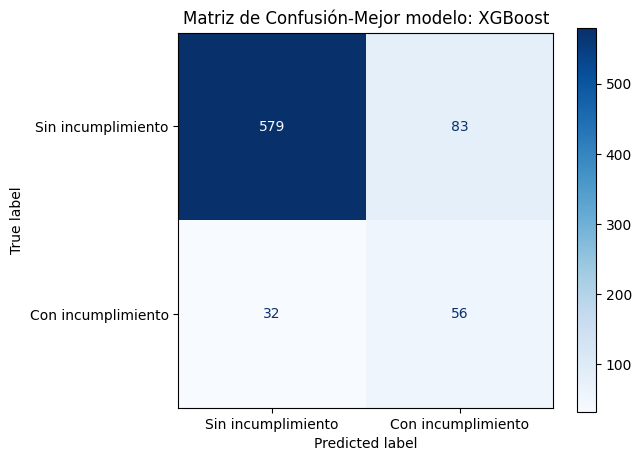

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["Sin incumplimiento", "Con incumplimiento"]
y_pred = (y_probs_mejor_modelo >= best_threshold).astype(int)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre_mejor_modelo}")
plt.tight_layout()
plt.show()

Las filas representan valores reales y las columnas las predicciones. Arriba izquierda: TN; arriba derecha: FP; abajo izquierda: FN; abajo derecha: TP. Los FN son los incumplidores aprobados que generan la pérdida económica.

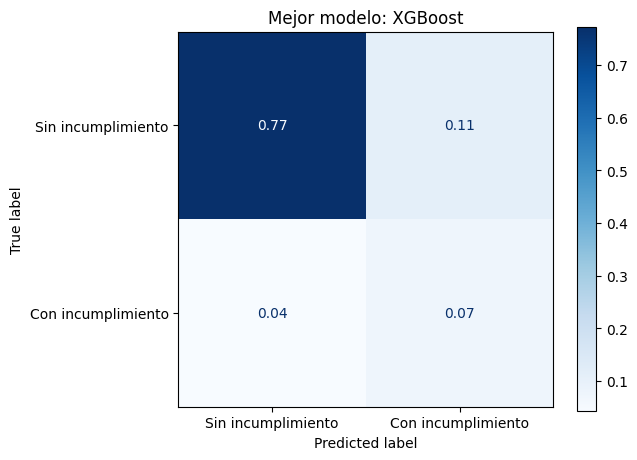

In [60]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre_mejor_modelo}")
plt.tight_layout()
plt.show()

normalize="all" divide cada casilla entre el total de prueba. No representa porcentajes por clase ni recall; las cuatro proporciones suman uno. Se conserva la matriz de conteos previa para evitar que el redondeo oculte casos.

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++

Decisión: no autorizar el despliegue inmediato de la propuesta del analista junior. La variable de atraso posterior permite anticipar artificialmente la etiqueta y SMOTE antes de dividir contamina la evaluación. Los resultados originales no sustentan una decisión de producción.

Candidato para un piloto controlado: XGBoost con calibración sigmoide, usando un umbral de rechazo de 0.1400. Se eligió por la mayor utilidad de validación entre los tres modelos y sus umbrales de la malla, tras ajustar complejidad solo con entrenamiento. Su ventaja de validación frente al segundo candidato es de 500 USD en 750 solicitudes: la diferencia es acotada y no se ha demostrado superioridad estadística entre ambos. Esta elección no demuestra superioridad universal ni reemplaza la validación temporal.

La base tiene 5,000 solicitudes y 586 incumplimientos (11.72%). Se entrenó con 3,500 registros, se seleccionó con 750 y se evaluó con 750 de prueba, manteniendo observaciones reales y prevalencia natural. La prueba contiene 88 incumplimientos. Los tres modelos completos aparecen en la tabla final; no se cambia el ganador si otra alternativa resulta mejor en prueba.




Resultado económico. En las 750 solicitudes de prueba, el umbral 0.50 produce 30,300 USD, mientras que el umbral validado produce 41,900 USD. Por cada 10,000 solicitudes comparables, equivalen a 404,000 USD y 558,667 USD, respectivamente: una diferencia de 154,667 USD. Aprobar todo produciría 296,000 USD por 10,000; rechazar todo produce cero bajo los costos del enunciado.

Con el umbral validado se aprueban 611 solicitudes: 579 buenos pagadores y 32 incumplidores. Se rechazan 56 incumplidores y 83 buenos pagadores. El umbral modifica tanto las pérdidas evitadas como las oportunidades comerciales perdidas.

Incertidumbre. El IC bootstrap 95% de utilidad del candidato es [465,333, 642,667] USD por 10,000. El intervalo de mejora frente a 0.50 es [78,667, 241,333] y frente a aprobar todo es [169,333, 365,333]. Estos intervalos son condicionales a los datos, al modelo y al umbral fijados; no aseguran ganancias futuras.

Factores principales del predictor calibrado, ordenados por aumento del log loss al permutar en validación:
1. utilizacion_credito: Fracción de la línea de crédito utilizada. Un uso elevado puede indicar menor holgura financiera. Aumento medio del log loss: 0.04426; desviación entre permutaciones: 0.00962.
2. consultas_buro_6m: Consultas al buró en seis meses; puede reflejar búsqueda reciente de financiamiento. Aumento medio del log loss: 0.04234; desviación entre permutaciones: 0.00798.
3. score_crediticio: Puntaje interno de historial crediticio (300-850). El diccionario asocia valores mayores con menor riesgo histórico. Aumento medio del log loss: 0.02556; desviación entre permutaciones: 0.00521.
4. relacion_deuda_ingreso: Deuda total dividida entre ingreso mensual; indica apalancamiento, no porcentaje de cuota mensual. Aumento medio del log loss: 0.01128; desviación entre permutaciones: 0.00313.
Condiciones para avanzar. Obtener fechas de evaluación y de actualización de atributos, confirmar la etiqueta observada a 90 días e incorporar identificadores para separar clientes cuando corresponda. Validar en un periodo posterior, verificar la estabilidad de las probabilidades y contrastar las ganancias y pérdidas reales con los 100/500 USD asumidos. Revisar la disponibilidad de cliente_premium, score, límite y deuda al decidir. Revisar el origen de la muestra, las unidades y coherencia de ingresos y antigüedad laboral. Ejecutar un piloto con revisión humana, registrar decisiones y resultados, monitorear mora, aprobación, calibración, utilidad y variaciones por segmentos; definir límites de deterioro y retorno al proceso previo.

La recomendación corresponde al mejor candidato bajo este experimento. La reducción de desempeño tras excluir información futura es una evaluación más creíble; no justifica recuperar variables que no existirán al momento de decidir.


### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

La auditoría muestra que un clasificador puede parecer excelente cuando incorpora información que solo aparece después de la decisión. El desempeño inicial no demuestra capacidad de anticipación: el diccionario identifica una variable futura y el propio archivo presenta separación perfecta por esa variable. El remuestreo previo a dividir, la selección del umbral en prueba y la elección automática de XGBoost agravan el problema.

La solución conserva las tres familias de árboles, la semilla 11, los nombres útiles del código y las funciones económicas, pero introduce un protocolo verificable: separar datos reales, excluir información futura, controlar complejidad con CV, calibrar dentro de entrenamiento, elegir modelo y umbral con validación y evaluar una política ya fijada en prueba. El balanceo de clases no es un fin en sí mismo. El objetivo es estimar riesgo y tomar decisiones que respondan a los costos.

Las brechas de log loss y AP se interpretan en el diagnóstico de ajuste. La existencia de un umbral de negocio cercano a 1/6 bajo calibración perfecta explica por qué 0.5 no es automáticamente apropiado. Sin embargo, el umbral empírico se selecciona con datos distintos a prueba y su beneficio se acompaña de referencias e incertidumbre. Ni SHAP ni las importancias por permutación prueban causalidad.

Herramientas de IA generativa utilizadas: ChatGPT (asistente Codex de OpenAI) como apoyo para revisar el notebook y el diccionario, proponer correcciones, redactar explicaciones, generar código y estructurar el reporte. Python, NumPy, pandas, scikit-learn, imbalanced-learn, XGBoost y SHAP son bibliotecas de ejecución/análisis, no LLMs. No se atribuye el trabajo a una versión específica de modelo que no haya sido verificada.

¿En qué casos fue más útil el LLM? En localizar usos problemáticos de y_test, relacionar la definición temporal de variables con fuga de información, detectar que modelo y nombre quedan apuntando al último ciclo, proponer métricas adicionales y preparar la comparación antes/después. También ayudó a organizar explicaciones de código y negocio en lenguaje claro.

¿Dónde es indispensable la intervención del experto? En confirmar cuándo está disponible cada atributo, verificar la definición y maduración de la etiqueta, decidir si la muestra representa solicitudes futuras, validar los costos de aprobación/rechazo y revisar si una ganancia estadística tiene sentido operativo. Se comprobó el nombre real default_90d, se cruzaron las definiciones con el PDF y se ejecutó el código sobre el CSV adjunto; aun así, las hipótesis sobre clientes, fechas y datos reales requieren confirmación del responsable del negocio. El LLM no sustituye esas comprobaciones ni autoriza el despliegue. Este texto reporta el apoyo efectivamente usado y no atribuye al estudiante acciones externas no realizadas.


### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**